# 37 - Módulo Q: turbidez esperada, montante e jusante, e validação

| | |
|---|---|
| **Tarefa do plano** | W3-06 (turbidez esperada e comparação montante/jusante), W3-07 (validação) |
| **O que faz** | Testa se a chuva e o caudal explicam a cor da água em cada troço, compara a fronteira com Marracuene, e valida as fórmulas com medições reais (GLORIA) |
| **Usa** | `qualidade_trocos.parquet`, medições por imagem, histórico de caudal e chuva, GLORIA (PANGAEA), lista de estações do GEMStat |
| **Produz** | `models/secchi_gloria.json`, tabelas e figuras em `reports/semana_3/` (prefixo 37) |

A ideia do plano: se soubermos a turbidez que a chuva e o caudal explicam, o que
sobra pode ser outra coisa (uma descarga, obras no rio). Este notebook testa se
essa ideia funciona aqui, troço a troço, e diz onde funciona e onde não.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, module_q
from ete import module_q_analysis as Q

cfg = config.load_config()
REPORTS = config.path(cfg, "reports", "semana_3")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 90)

## 1. A chuva e o caudal explicam a cor da água?

Primeira tentativa, a do plano: mês a mês. **Não funcionou**: com uma ou duas
imagens por mês, o valor do mês não se explica pela chuva do mês (o modelo ficou
pior do que usar só a época do ano, em todos os troços).

Segunda tentativa, a que fica: **imagem a imagem**. Cada imagem recebe o caudal
do dia e dos dias anteriores, a chuva dos últimos 3, 7 e 30 dias, a época do ano
e a maré à hora do satélite. Um modelo por troço; cada ano é previsto por um
modelo que nunca o viu.

,nome,imagens,anos,r2_chuva_caudal_mare,r2_epoca_do_ano,corr_com_caudal,modelo_fiavel
troco,,,,,,,
Q1,Q1 fronteira / Ressano Garcia,416,10,0.030,-0.280,0.380,False
Q2,Q2 km 37 a 74,425,10,0.210,0.010,0.520,False
Q3,Q3 km 74 a 110,457,10,0.020,-0.180,-0.110,False
Q4,Q4 Magude,424,10,0.200,0.050,0.460,False
Q5,Q5 Xinavane,773,10,0.210,0.040,0.520,False
Q6,Q6 km 184 a 221,772,10,-0.020,-0.040,0.130,False
Q7,Q7 Manhiça,1129,21,-0.000,-0.020,0.090,False
Q8,Q8 Marracuene,1303,21,0.000,-0.020,0.140,False
Q9,Q9 foz / estuário,1310,21,0.520,0.120,0.420,True


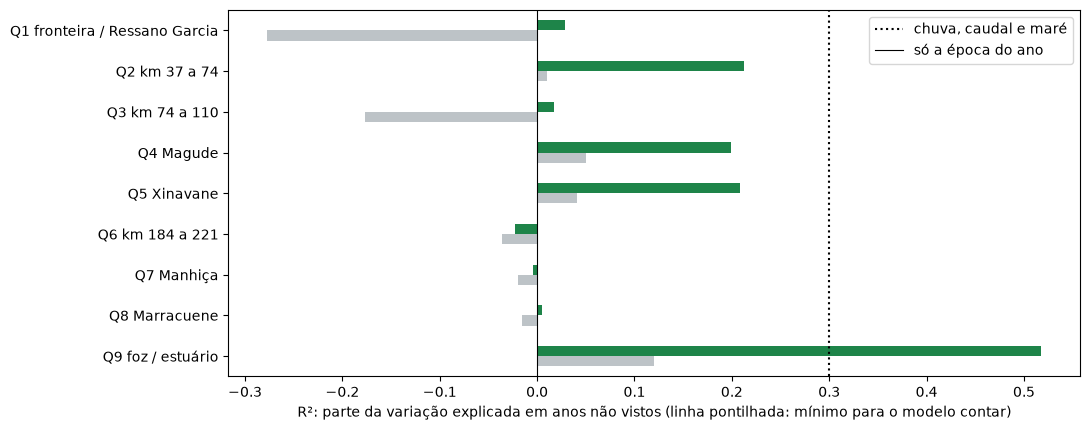

In [2]:
data, skill, images = Q.expected_turbidity(cfg, Q.monthly_dataset(cfg))
skill.round(3).to_csv(REPORTS / "37_turbidez_esperada_desempenho.csv")
ax = skill[["r2_chuva_caudal_mare", "r2_epoca_do_ano"]].set_index(skill["nome"]).plot.barh(figsize=(11, 4.4), color=["#1e8449", "#bdc3c7"])
ax.invert_yaxis(); ax.axvline(Q.MIN_SKILL, color="black", linestyle=":"); ax.axvline(0, color="black", linewidth=0.8); ax.set_ylabel("")
ax.set_xlabel("R²: parte da variação explicada em anos não vistos (linha pontilhada: mínimo para o modelo contar)")
ax.legend(["chuva, caudal e maré", "só a época do ano"]); plt.tight_layout(); plt.savefig(REPORTS / "37_turbidez_esperada.png", dpi=110)
skill.round(2)

**Como ler.** `r2_chuva_caudal_mare` é a parte da variação da cor que o modelo
explica em anos que não viu. Abaixo de 0,2 o modelo explica pouco de mais, e dizer
"esta turbidez não se explica pela chuva" não teria significado: nesses troços a
plataforma **não** dá esse aviso.

**Leitura.** Só perto da foz o modelo explica uma parte útil da variação. No resto
do rio fica perto de zero: com estes dados, a ideia "turbidez esperada pela
chuva e pelo caudal" não se sustenta troço a troço.

**Porque falha na maior parte dos troços** (hipóteses, por ordem de probabilidade):

1. O caudal usado é o de Marracuene, de um modelo global. A montante, o caudal
   real depende das barragens e de afluentes que esse número não mostra.
2. Nos troços estreitos há poucas imagens e só desde 2017.
3. O troço Q8 junta 37 km de rio com e sem maré.

Para os troços de Marracuene, o modelo de produção (notebook 35), que usa também
a última medição por satélite, explica cerca de dois terços da variação.

## 2. Meses com turbidez acima do explicado

Só nos troços onde o modelo conta.

troços com modelo fiável: Q9 foz / estuário


,nome,month,ndti,esperado,residuo,caudal_m3s,chuva_mm
2101,Q9 foz / estuário,2014-06,-0.083,-0.295,0.212,1.534,8.645
2108,Q9 foz / estuário,2015-01,0.009,-0.152,0.161,49.959,118.818
2102,Q9 foz / estuário,2014-07,-0.114,-0.241,0.127,0.743,8.188
2053,Q9 foz / estuário,2010-06,-0.033,-0.156,0.123,13.601,10.894
2151,Q9 foz / estuário,2018-08,-0.078,-0.200,0.123,1.541,16.744
2118,Q9 foz / estuário,2015-11,-0.044,-0.162,0.118,7.305,65.464
2072,Q9 foz / estuário,2012-01,0.006,-0.105,0.111,80.598,140.588
2074,Q9 foz / estuário,2012-03,-0.009,-0.112,0.104,15.859,82.637
2219,Q9 foz / estuário,2024-04,0.015,-0.064,0.103,36.992,97.962
2054,Q9 foz / estuário,2010-07,-0.147,-0.242,0.096,6.915,11.130


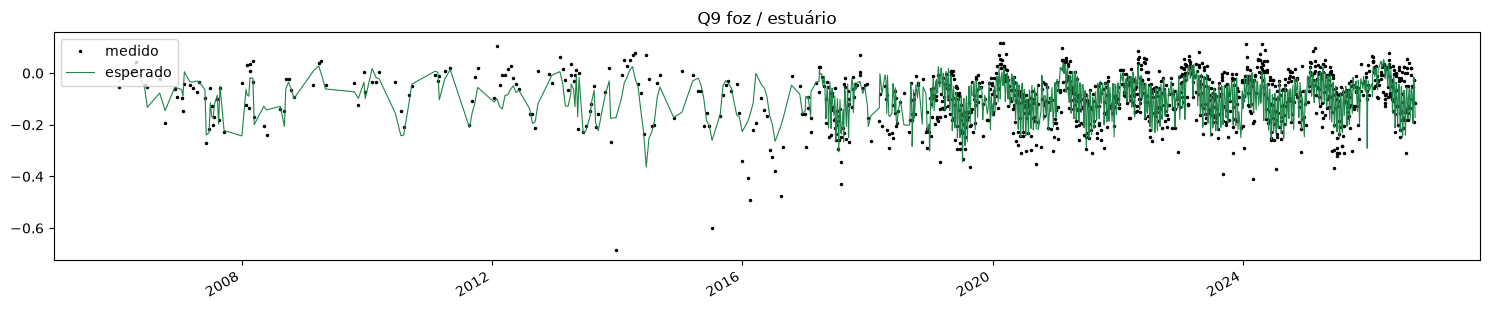

In [3]:
reliable = skill[skill["modelo_fiavel"]].index
unexplained = data[data["nao_explicada"] == True][["nome", "month", "ndti", "esperado", "residuo", "caudal_m3s", "chuva_mm"]]
unexplained.round(4).to_csv(REPORTS / "37_meses_acima_do_explicado.csv", index=False)
print("troços com modelo fiável:", ", ".join(skill.loc[reliable, "nome"]) or "nenhum")
if len(reliable):
    fig, axes = plt.subplots(len(reliable), 1, figsize=(15, 3.2 * len(reliable)), squeeze=False)
    for ax, section in zip(axes[:, 0], reliable):
        group = images[images["troco"] == section].set_index("date")
        group["ndti"].plot(ax=ax, style=".", color="black", markersize=3, label="medido"); group["esperado"].plot(ax=ax, color="#1e8449", linewidth=0.8, label="esperado")
        ax.set_title(skill.loc[section, "nome"]); ax.set_xlabel(""); ax.legend(loc="upper left")
    plt.tight_layout(); plt.savefig(REPORTS / "37_medido_e_esperado.png", dpi=110)
unexplained.sort_values("residuo", ascending=False).head(12)

**Leitura.** A tabela lista os meses em que a água esteve mais turva do que o
modelo esperava. Antes de qualquer conclusão, cada caso deve ser visto: imagem do
dia, notícias, registos de descargas de barragens. O modelo aponta, não acusa.

## 3. Montante e jusante: a água já chega turva à fronteira?

Comparação entre o troço da fronteira (Q1) e o de Marracuene (Q8), nos meses em
que os dois foram medidos pelo Sentinel-2.

,valor
meses,110.000
correlacao,-0.057
mediana_montante,-0.023
mediana_jusante,-0.036
meses_mais_turva_a_jusante,0.464
diferenca_mediana,-0.017


,epoca,chuvosa,seca
troco,nome,,
Q1,Q1 fronteira / Ressano Garcia,0.020,-0.086
Q2,Q2 km 37 a 74,0.005,-0.063
Q3,Q3 km 74 a 110,0.030,0.060
Q4,Q4 Magude,-0.008,-0.053
Q5,Q5 Xinavane,-0.029,-0.059
Q6,Q6 km 184 a 221,-0.077,-0.083
Q7,Q7 Manhiça,-0.033,-0.036
Q8,Q8 Marracuene,-0.029,-0.040
Q9,Q9 foz / estuário,-0.055,-0.104


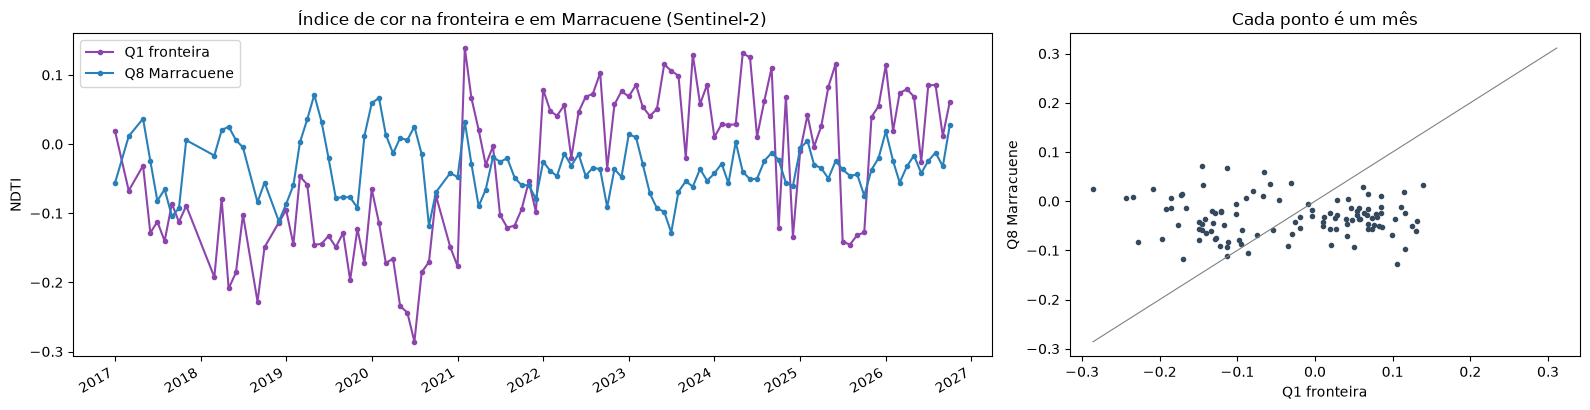

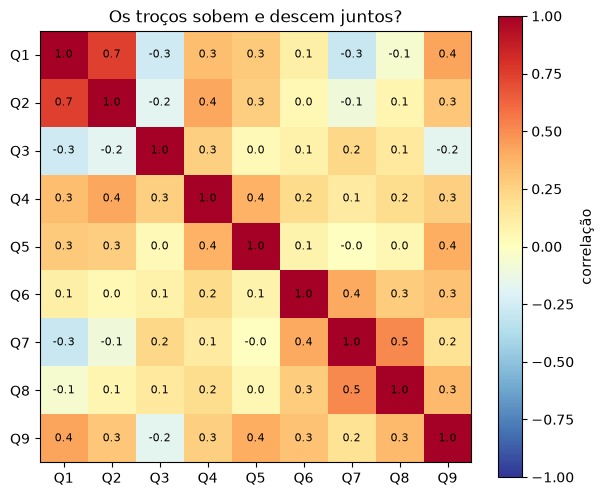

In [4]:
result = Q.upstream_downstream(data, "Q1", "Q8")
if result.get("meses", 0) >= 12:
    both = result.pop("tabela")
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.8, 1]})
    both.index = pd.to_datetime(both.index)
    both[["Q1", "Q8"]].plot(ax=axes[0], marker=".", color=["#8e44ad", "#2980b9"]); axes[0].legend(["Q1 fronteira", "Q8 Marracuene"]); axes[0].set_ylabel("NDTI"); axes[0].set_xlabel("")
    axes[0].set_title("Índice de cor na fronteira e em Marracuene (Sentinel-2)")
    axes[1].plot(both["Q1"], both["Q8"], ".", color="#34495e"); lims = [both.min().min(), both.max().max()]; axes[1].plot(lims, lims, color="grey", linewidth=0.8)
    axes[1].set_xlabel("Q1 fronteira"); axes[1].set_ylabel("Q8 Marracuene"); axes[1].set_title("Cada ponto é um mês")
    plt.tight_layout(); plt.savefig(REPORTS / "37_montante_e_jusante.png", dpi=110)
pd.Series(result).to_frame("valor").to_csv(REPORTS / "37_montante_e_jusante.csv")
between = data.pivot(index="month", columns="troco", values="ndti_s2").corr(min_periods=24)
between.round(2).to_csv(REPORTS / "37_correlacao_entre_trocos.csv")
fig, ax = plt.subplots(figsize=(6.2, 5.2)); im = ax.imshow(between.values, cmap="RdYlBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(between)), between.columns); ax.set_yticks(range(len(between)), between.index)
for (i, j), v in np.ndenumerate(between.values):
    if np.isfinite(v):
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="correlação"); ax.set_title("Os troços sobem e descem juntos?"); plt.tight_layout(); plt.savefig(REPORTS / "37_correlacao_entre_trocos.png", dpi=110)
along = data.groupby(["troco", "nome", "epoca"])["ndti_s2"].median().unstack("epoca")
along.round(3).to_csv(REPORTS / "37_cor_ao_longo_do_rio.csv")
display(pd.Series(result).to_frame("valor")); along.round(3)

**Como ler**

- `correlacao`: se os dois troços sobem e descem juntos, a turbidez de Marracuene
  vem em boa parte de montante.
- `meses_mais_turva_a_jusante`: em que parte dos meses a água está mais turva em
  Marracuene do que na fronteira.
- O quadro colorido mostra a correlação entre todos os pares de troços: troços
  vizinhos parecem-se, troços afastados quase não.
- A segunda tabela mostra a cor mediana ao longo do rio, na época seca e na
  chuvosa.

**Leitura.** A cor da água em Marracuene não acompanha, mês a mês, a cor na
fronteira. A resposta à pergunta transfronteiriça, com estes dados, é: **não se
vê o sinal da fronteira em Marracuene**. Entre os dois pontos há 250 km de rio,
afluentes, regadios e, no fim, a maré, que domina a cor a jusante.

**Cuidados.** O índice compara cores, não cargas de sedimento: dois troços com
fundos e profundidades diferentes podem ter cores diferentes com a mesma água. E
em Q1 o rio é estreito, com poucos píxeis por imagem. A pergunta "de onde vem o
sedimento" só fica respondida com medições no rio nos dois pontos.

## 4. Validação das fórmulas com medições reais (GLORIA)

O GLORIA junta refletância medida à superfície da água com turbidez, sólidos
suspensos, clorofila-a e disco de Secchi, em centenas de lagos, rios e costas do
mundo. Serve para testar as **fórmulas**. Não testa as nossas imagens.

,amostras,r2_log,correlacao_log,fator_tipico,razao_mediana,nota
teste,,,,,,
"turbidez: Dogliotti 2015, banda vermelha",361,0.580,0.780,2.530,0.920,fórmula usada em `turbidez_fnu`
"sólidos suspensos: Nechad 2010, 665 nm",1354,0.480,0.700,2.740,1.070,fórmula usada em `tss_mg_l`
clorofila-a vs NDCI: águas pouco turvas (TSS < 20 mg/L),710,NaN,0.390,NaN,NaN,no GLORIA as águas turvas são sobretudo lagos com algas; no Incomáti o NDCI segue o se...
clorofila-a vs NDCI: águas turvas (TSS >= 20 mg/L),224,NaN,0.820,NaN,NaN,no GLORIA as águas turvas são sobretudo lagos com algas; no Incomáti o NDCI segue o se...
sólidos suspensos vs NDTI,1354,NaN,0.520,NaN,NaN,o NDTI ordena as águas pela carga de sedimento?
transparência (Secchi) a partir da refletância no vermelho,1346,0.720,0.850,1.750,1.000,"relação ajustada aqui e usada em `secchi_m` (validação cruzada, 5 partes)"


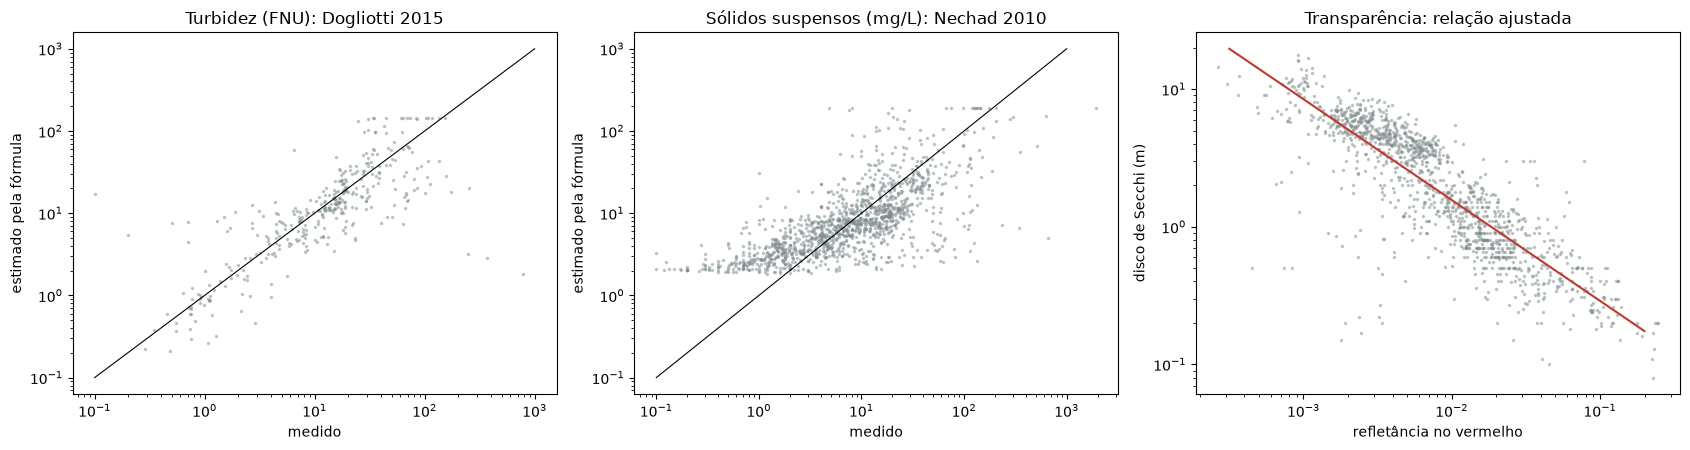

In [5]:
validation, samples = Q.gloria_validation(cfg)
validation.round(3).to_csv(REPORTS / "37_validacao_gloria.csv")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, measured, estimate, title in ((axes[0], "Turbidity", "fnu_dogliotti", "Turbidez (FNU): Dogliotti 2015"), (axes[1], "TSS", "tss_nechad", "Sólidos suspensos (mg/L): Nechad 2010")):
    ok = samples[measured].gt(0) & samples[estimate].gt(0)
    ax.loglog(samples.loc[ok, measured], samples.loc[ok, estimate], ".", color="#7f8c8d", alpha=0.4, markersize=3)
    ax.plot([0.1, 1000], [0.1, 1000], color="black", linewidth=0.8); ax.set_xlabel("medido"); ax.set_ylabel("estimado pela fórmula"); ax.set_title(title)
secchi = json.loads((ROOT / "models" / "secchi_gloria.json").read_text())
ok = samples["Secchi_depth"].gt(0)
axes[2].loglog(samples.loc[ok, "rho_665"], samples.loc[ok, "Secchi_depth"], ".", color="#7f8c8d", alpha=0.4, markersize=3)
x = np.logspace(-3.5, -0.7, 50); axes[2].plot(x, 10 ** (secchi["intercept"] + secchi["slope"] * np.log10(x)), color="#c0392b")
axes[2].set_xlabel("refletância no vermelho"); axes[2].set_ylabel("disco de Secchi (m)"); axes[2].set_title("Transparência: relação ajustada")
plt.tight_layout(); plt.savefig(REPORTS / "37_validacao_gloria.png", dpi=110)
validation.round(2)

**Como ler**

- `r2_log` e `correlacao_log`: quanto a fórmula acompanha a medição (em escala
  logarítmica, porque os valores vão de menos de 1 a mais de 1000).
- `fator_tipico`: o erro típico. 2,5 quer dizer que a estimativa pode ser duas
  vezes e meia maior ou menor do que a medição.
- `razao_mediana`: perto de 1 = sem desvio sistemático.

**Leitura honesta.** As fórmulas publicadas acertam em média e ordenam bem as
águas, mas uma estimativa isolada pode falhar por um fator de 2 a 3, mesmo com
refletância medida à superfície, em condições ideais. Com imagens de satélite
corrigidas para terra, o erro é maior. Por isso a plataforma usa a turbidez em
FNU e os sólidos em mg/L só como **ordem de grandeza**, e baseia os alertas no
índice de cor comparado com o seu próprio normal.

## 5. Medições no local: GEMStat e disco de Secchi

In [6]:
import geopandas as gpd
stations = pd.read_csv(config.path(cfg, "water_quality", "validacao", "gemstat", "GEMStat_station_metadata.csv", mkdir=False), sep=None, engine="python", encoding="latin-1", on_bad_lines="skip")
points = gpd.GeoDataFrame(stations, geometry=gpd.points_from_xy(pd.to_numeric(stations["Longitude"], errors="coerce"), pd.to_numeric(stations["Latitude"], errors="coerce")), crs=4326)
basin = gpd.read_file(ROOT / "data" / "raw" / "aoi" / "incomati_basin.geojson").union_all()
inside = points[points.within(basin)]
print(f"GEMStat (arquivo de fevereiro de 2026): {len(stations):,} estações no mundo; dentro da bacia do Incomáti: {len(inside)}")
field = pd.read_csv(config.path(cfg, "water_quality", "campo", "medicoes_secchi.csv", mkdir=False))
print(f"medições próprias (disco de Secchi / turbidímetro) registadas: {len(field)}")

GEMStat (arquivo de fevereiro de 2026): 22,981 estações no mundo; dentro da bacia do Incomáti: 0
medições próprias (disco de Secchi / turbidímetro) registadas: 0


**Leitura.** O arquivo mundial do GEMStat não tem nenhuma estação na bacia do
Incomáti. Não há, portanto, medições públicas no rio para validar valores
absolutos. A equipa decidiu, a 12 de outubro de 2026, não fazer medições no
local nesta fase (tarefas W2-16 e W3-08). **Não haverá, portanto, validação
local:** os valores em FNU, mg/L e metros de transparência ficam como estimativas
e não devem ser apresentados ao público como medições.

## O que está validado e o que não está

| Afirmação | Estado | Base |
|---|---|---|
| O índice de cor é repetível entre dois satélites independentes | **validado** | notebooks 29 e 35 |
| As fórmulas de turbidez e sólidos acertam em média em águas reais | **validado**, com erro típico de um fator 2 a 3 | secção 4 (GLORIA) |
| Os valores em FNU e mg/L estão certos no Incomáti | **não validado, e não será nesta fase** | sem medições no rio (decisão da equipa) |
| A transparência estimada está certa no Incomáti | **não validado, e não será nesta fase** | sem disco de Secchi (decisão da equipa) |
| A turbidez acima do explicado indica poluição | **não se pode afirmar** | o modelo aponta meses a verificar |
| A clorofila-a pode ser medida aqui pelo NDCI | **não** | segue o sedimento (notebook 34) |
| pH, oxigénio, nutrientes, metais, bactérias | **fora do alcance do satélite** | plano, Parte I |